# 01 — Exploratory Data Analysis and Data Quality Assessment

## 1. Introduction and Research Context

This study forecasts **NVIDIA's next-session split-adjusted closing price in USD**. NVDA is the target instrument; SPY and XLK provide broad-market and technology-sector context. Observations are aligned by trading session rather than calendar day.

This notebook investigates the data sources, validates the observations and examines the statistical properties relevant to forecasting. It calls reusable Python functions, displays their intermediate representations and demonstrates their behaviour. EDA investigates levels, changes, tails, volatility and relationships; it does not establish forecasting skill or a profitable strategy.

**Scope:** all numerical analyses and charts use the **2015–2022 training period**. The bounded loader decodes only the selected price observations. Later quote values and price metadata are not decoded. No data are downloaded, corrected or discarded silently.

Run all cells in order in the existing environment, from the repository root or notebooks directory. Loading and validation algorithms live in `market_forecasting.data`; calendar comparison lives in `market_forecasting.calendar`. Charts, tables and execution results remain in this authoritative notebook; running it creates no separate report or notebook copy.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display
from market_forecasting.data import (
    load_training_panel, load_yahoo_records, price_quality, validate_prices,
    snapshot_provenance, recorded_splits,
)
from market_forecasting.calendar import audit_sessions

ROOT = Path.cwd() if (Path.cwd() / "configs/nvda.json").exists() else Path.cwd().parent
assert (ROOT / "configs/nvda.json").exists(), "Start from the repository or notebooks directory."
config = json.loads((ROOT / "configs/nvda.json").read_text())
START, END = pd.Timestamp(config["start"]), pd.Timestamp(config["train_end"])
assert END < pd.Timestamp(config["validation_end"]) < pd.Timestamp(config["test_end"])
assert END == pd.Timestamp("2022-12-31"), "Review the EDA boundary before changing the training period."
SYMBOLS = [config["target_ticker"], *config["context_tickers"]]
get_ipython().run_line_magic("matplotlib", "inline")
COLORS = {"NVDA": "#2563eb", "SPY": "#d97706", "XLK": "#059669"}
pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})


def dated_axis(ax):
    """Use concise dates without overlapping labels."""
    locator = mdates.AutoDateLocator(minticks=4, maxticks=9)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlim(START, END)


def show_figure(fig):
    """Display a figure inline without generating a separate artifact."""
    plt.show()
    plt.close(fig)

print(f"Permitted observations: {START.date()} to {END.date()}")

Permitted observations: 2015-01-01 to 2022-12-31


## 2. Data Sources and Provenance

The acquisition script obtained daily Yahoo Finance chart responses on **11 October 2026**. Frozen JSON files contain UTC timestamps, OHLC prices, volume and adjusted-close arrays. Requested file coverage is 2015–2025; it is distinct from the permitted analysis interval. A later download could revise history, so the original snapshots are retained.

The implementation used below has four responsibilities:

1. `snapshot_provenance()` compares SHA-256 checksums with the acquisition record. It hashes opaque bytes and extracts identifiers without decoding price histories or the audit's full-period statistics. Identity does not independently certify vendor accuracy.
2. `load_training_panel()` passes the configured start and training end to `load_yahoo_snapshot()`. Its bounded reader locates the permitted timestamp positions **before decoding quote values**.
3. UTC timestamps are converted to the recorded exchange timezone before deriving timezone-naive session dates. The DataFrame retains Close and Adjusted Close separately; `validate_prices()` rejects invalid observations without repairing them.
4. The panel loader checks agreement across instrument indexes. The independent exchange-calendar comparison in Section 4 additionally detects sessions missing from every series.

**Temporal isolation:** selecting the permitted interval before numerical validation prevents unused later quote values from affecting the validation of training observations. Synthetic tests verify that selected values are preserved and excluded quote tokens never reach the numeric decoder.

**Access limitation:** this dependency-free reader supports the frozen chronological Yahoo scalar-array schema, not arbitrary JSON feeds. It scans bytes to locate fields, reads timestamps through the first date after the boundary, and decodes only selected quote tokens. It rejects ambiguous required fields, but cannot certify ordering or completeness in an intentionally unread tail. Checksum identity and bounded numerical validation are separate checks. An unbounded loader is available for administrative use; this notebook always uses the bounded route.

In [2]:
audit_path = ROOT / "docs/data_verification.json"
provenance = [snapshot_provenance(ROOT / "data/raw" / f"{symbol}_yahoo_snapshot.json",
                                audit_path, symbol) for symbol in SYMBOLS]
panel = load_training_panel(ROOT, config)
stock = panel[config["target_ticker"]]
for frame in panel.values():
    assert frame.index.min() >= START and frame.index.max() <= END
    validate_prices(frame)
display(pd.DataFrame(provenance).set_index("instrument"))

,snapshot,retrieved_utc,checksum_matches,sha256
instrument,,,,
NVDA,NVDA_yahoo_snapshot.json,2026-10-11T09:07:25.380128+00:00,True,e0903f6a59e349426fe0da5262ec7ec7c78c37b7350ef2...
SPY,SPY_yahoo_snapshot.json,2026-10-11T09:07:25.380128+00:00,True,1d9cb7d41005575765a48353ab04cd1753761382989420...
XLK,XLK_yahoo_snapshot.json,2026-10-11T09:07:25.380128+00:00,True,daca5933dda08edbb09e6d460508fb37dafe0f052b85a5...


The example below shows the first two NVDA source records and resulting DataFrame rows. Quote arrays become columns; adjclose is renamed adj_close. The timestamp becomes an exchange-local session label, not a predictor. Volume remains visible for integrity checks but is excluded from modelling.

| Field | Meaning and use |
|---|---|
| open / close | First / final session prices, on the retained historical basis; Close is the target field |
| high / low | Maximum / minimum session prices; used to check internal OHLC consistency |
| adj_close | Vendor dividend-adjusted reference price, retained separately from Close |
| volume | Reported share volume; numerical auditing only, excluded from forecasting features |
| date index | Exchange-local session label derived from the UTC timestamp |


In [3]:
# The same restricted record reader underlies load_yahoo_snapshot().
example = load_yahoo_records(ROOT / "data/raw/NVDA_yahoo_snapshot.json",
                            start=START, end=stock.index[1])
source_example = pd.DataFrame({"timestamp_utc_seconds": example["timestamp"],
    **example["indicators"]["quote"][0],
    "adjclose": example["indicators"]["adjclose"][0]["adjclose"]})
display(source_example)
display(stock.head(2))
assert source_example["close"].tolist() == stock["close"].head(2).tolist()
assert len(source_example) == 2

,timestamp_utc_seconds,high,close,volume,open,low,adjclose
0,1420209000,0.50700,0.50325,113680000,0.50325,0.49525,0.481884
1,1420468200,0.50475,0.49475,197952000,0.50325,0.49250,0.473745


,high,close,volume,open,low,adj_close
date,,,,,,
2015-01-02,0.50700,0.50325,113680000,0.50325,0.49525,0.481884
2015-01-05,0.50475,0.49475,197952000,0.50325,0.49250,0.473745


## 3. Dataset Structure

**head()** and **tail()** expose boundary records, not the quality of the entire table. **shape** gives rows × columns; **dtypes** identifies storage types; **info()** reports non-null counts and memory use. The DatetimeIndex labels sessions. Inspecting every instrument avoids assuming that one valid table guarantees the others are valid.

In [4]:
structure = pd.DataFrame({s: {"rows": len(f), "columns": f.shape[1],
    "first_session": str(f.index.min().date()), "last_session": str(f.index.max().date()),
    "index_type": type(f.index).__name__} for s, f in panel.items()}).T
display(structure)
for symbol, frame in panel.items():
    print(f"\n{symbol}: shape={frame.shape}")
    display(frame.head(3))
    display(frame.tail(3))
    frame.info()
display(pd.DataFrame({s: f.dtypes.astype(str) for s, f in panel.items()}))
display(Markdown(f"Each series has **{len(stock):,} sessions** and **{stock.shape[1]} columns**, "
    f"from **{stock.index.min().date()}** to **{stock.index.max().date()}**. Observed session endpoints "
    "need not match calendar-date partition boundaries. No validation or test observations appear here."))

,rows,columns,first_session,last_session,index_type
NVDA,2014,6,2015-01-02,2022-12-30,DatetimeIndex
SPY,2014,6,2015-01-02,2022-12-30,DatetimeIndex
XLK,2014,6,2015-01-02,2022-12-30,DatetimeIndex



NVDA: shape=(2014, 6)


,high,close,volume,open,low,adj_close
date,,,,,,
2015-01-02,0.50700,0.50325,113680000,0.50325,0.49525,0.481884
2015-01-05,0.50475,0.49475,197952000,0.50325,0.49250,0.473745
2015-01-06,0.49600,0.47975,197764000,0.49550,0.47925,0.459381


,high,close,volume,open,low,adj_close
date,,,,,,
2022-12-28,14.262,14.036,351066000,13.927,13.884,13.989228
2022-12-29,14.683,14.603,354923000,14.402,14.227,14.554338
2022-12-30,14.629,14.614,310490000,14.334,14.233,14.565301


<class 'pandas.DataFrame'>
DatetimeIndex: 2014 entries, 2015-01-02 to 2022-12-30
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   high       2014 non-null   float64
 1   close      2014 non-null   float64
 2   volume     2014 non-null   int64  
 3   open       2014 non-null   float64
 4   low        2014 non-null   float64
 5   adj_close  2014 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 110.1 KB

SPY: shape=(2014, 6)


...

,close,low,volume,high,open,adj_close
date,,,,,,
2015-01-02,20.635000,20.530001,16990400,20.855000,20.805000,18.041687
2015-01-05,20.320000,20.260000,14389400,20.559999,20.559999,17.766268
2015-01-06,20.075001,19.980000,17491200,20.379999,20.379999,17.552065


,close,low,volume,high,open,adj_close
date,,,,,,
2022-12-28,60.715000,60.645000,10362600,62.134998,61.560001,59.199345
2022-12-29,62.305000,61.305000,10954200,62.514999,61.310001,60.749653
2022-12-30,62.220001,61.275002,8905800,62.255001,61.660000,60.666771


<class 'pandas.DataFrame'>
DatetimeIndex: 2014 entries, 2015-01-02 to 2022-12-30
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   close      2014 non-null   float64
 1   low        2014 non-null   float64
 2   volume     2014 non-null   int64  
 3   high       2014 non-null   float64
 4   open       2014 non-null   float64
 5   adj_close  2014 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 110.1 KB


,NVDA,SPY,XLK
adj_close,float64,float64,float64
close,float64,float64,float64
high,float64,float64,float64
low,float64,float64,float64
open,float64,float64,float64
volume,int64,int64,int64


Each series has **2,014 sessions** and **6 columns**, from **2015-01-02** to **2022-12-30**. Observed session endpoints need not match calendar-date partition boundaries. No validation or test observations appear here.

## 4. Data Quality Assessment

A **null** is an absent cell; a **missing session** is an absent row on an expected exchange session. Weekends and market holidays are not missing trading observations.

The existing validator rejects empty data, malformed dates, duplicate or unordered sessions, missing/nonfinite numbers, non-positive prices, negative volume and inconsistent OHLC ranges. It does not repair data or certify adjustment semantics. Diagnostic counts below make those checks visible.

The existing calendar audit independently compares dates with NASDAQ sessions for NVDA and the documented NYSE proxy for SPY/XLK. Index agreement alone cannot detect a date absent from all instruments. Half-days remain sessions. This is a calendar-library comparison, not exchange certification.

`price_quality()` supplies the counts used by `validate_prices()` itself. Displaying this shared result prevents a separate notebook implementation of the financial rules. Null and nonfinite counts overlap because null numerical values are also nonfinite; these columns must not be added as independent error totals. Zero volume is reported but not automatically rejected. A clean audit supports retaining the observations, not inventing a cleaning step.

In [5]:
quality_rows, calendar_rows, audits = [], [], {}
for symbol, frame in panel.items():
    quality_rows.append({"instrument": symbol, **price_quality(frame)})
    validate_prices(frame)
    audit = audit_sessions(frame.index, START, END, "NASDAQ" if symbol == "NVDA" else "NYSE")
    audits[symbol] = audit
    calendar_rows.append({"instrument": symbol, "calendar": audit["calendar"],
        "expected": audit["expected_sessions"], "observed": audit["observed_sessions"],
        "missing_sessions": len(audit["missing"]), "unexpected_sessions": len(audit["unexpected"])})
    assert not audit["missing"] and not audit["unexpected"], "Investigate coverage; never fill silently."
    assert frame.index.equals(stock.index)
quality = pd.DataFrame(quality_rows).set_index("instrument")
calendar_summary = pd.DataFrame(calendar_rows).set_index("instrument")
display(quality)
display(calendar_summary)
display(pd.DataFrame({s: a["sessions_by_year"] for s, a in audits.items()}).rename_axis("year"))
closures = pd.date_range(START, END, freq="D").difference(stock.index)
weekend_count = int((closures.dayofweek >= 5).sum())
weekday_closures = closures[closures.dayofweek < 5]
display(pd.DataFrame({"weekday_non_session_examples": weekday_closures[:8]}))
display(Markdown(f"All three series pass the validator and calendar checks: **{len(stock):,} expected and observed sessions** "
    f"each, with no missing or unexpected sessions. There are **{len(closures)} non-session calendar days**: "
    f"{weekend_count} weekend days and {len(weekday_closures)} weekday closures. "
    "These are not missing records. No prices were filled, reordered, corrected or discarded."))

,null_cells,nonfinite_cells,duplicate_dates,ordered,nonpositive_prices,negative_volume,zero_volume,invalid_OHLC_rows
instrument,,,,,,,,
NVDA,0,0,0,True,0,0,0,0
SPY,0,0,0,True,0,0,0,0
XLK,0,0,0,True,0,0,0,0


,calendar,expected,observed,missing_sessions,unexpected_sessions
instrument,,,,,
NVDA,NASDAQ,2014,2014,0,0
SPY,NYSE,2014,2014,0,0
XLK,NYSE,2014,2014,0,0


,NVDA,SPY,XLK
year,,,
2015,252,252,252
2016,252,252,252
2017,251,251,251
2018,251,251,251
2019,252,252,252
2020,253,253,253
2021,252,252,252
2022,251,251,251


,weekday_non_session_examples
0,2015-01-01
1,2015-01-19
2,2015-02-16
3,2015-04-03
4,2015-05-25
5,2015-07-03
6,2015-09-07
7,2015-11-26


All three series pass the validator and calendar checks: **2,014 expected and observed sessions** each, with no missing or unexpected sessions. There are **908 non-session calendar days**: 835 weekend days and 73 weekday closures. These are not missing records. No prices were filled, reordered, corrected or discarded.

### Demonstrating rejection and independent coverage checks

A successful audit is easier to interpret when the failure behaviour is visible. The first example places one missing Close in a **copy** of two historical records, calls the actual diagnostic and validator, and captures the expected rejection. The original data are unchanged. The second removes the same session from all three indexes: alignment still holds, but the actual calendar auditor detects the gap. These deliberate examples are demonstrations, not observed dataset defects.

In [6]:
invalid_example = stock.head(2).copy()
invalid_example.loc[invalid_example.index[0], "close"] = np.nan
display(pd.DataFrame([price_quality(invalid_example)], index=["deliberately invalid copy"]))
try:
    validate_prices(invalid_example)
except ValueError as error:
    print(f"Expected validator rejection: {error}")
else:
    raise AssertionError("The validator must reject a missing Close")
assert stock.close.notna().all()

missing_date = stock.index[1]
altered_indexes = {symbol: frame.index.delete(1) for symbol, frame in panel.items()}
assert all(index.equals(altered_indexes["NVDA"]) for index in altered_indexes.values())
gap_audit = audit_sessions(altered_indexes["NVDA"], START, END, "NASDAQ")
assert gap_audit["missing"] == [str(missing_date.date())]
print(f"Aligned instruments can still omit a session: calendar audit detects {gap_audit['missing']}")

,null_cells,nonfinite_cells,duplicate_dates,ordered,nonpositive_prices,negative_volume,zero_volume,invalid_OHLC_rows
deliberately invalid copy,1,1,0,True,0,0,0,0


Expected validator rejection: Missing or non-finite prices/volume
Aligned instruments can still omit a session: calendar audit detects ['2015-01-05']


## 5. Financial Data Conventions

The target is Yahoo **Close on the project's retrospective split-adjusted basis**. Earlier prices are expressed on a later share basis, not the contemporaneous quoted dollar basis. **Adjusted Close** additionally accounts for dividend adjustments; it remains a reference field rather than the target. Close-derived returns are price returns, not dividend-reinvested total returns.

A 4-for-1 split changes share count and the per-share quote without itself creating a 75% economic loss. The recorded 2021 NVDA split provides a continuity check. The later 2024 split also affects the retrospective historical share basis; no 2024 quotes are inspected here. No split multiplier is reapplied. This dataset is not a reconstruction of point-in-time corporate-action vintages.

Volume is checked for invalid numbers but remains excluded from modelling because its adjustment semantics have not been independently verified. Numeric validity and apparent split continuity cannot establish that convention.

The ratio $A_t/C_t$ describes the vendor's two price fields; it does not independently verify them against exchange records. See the established [data conventions](../docs/DATA_CONVENTIONS.md).

In [7]:
adjustment_summary = pd.DataFrame({s: {"min_adj_to_close": (f.adj_close / f.close).min(),
    "max_adj_to_close": (f.adj_close / f.close).max(),
    "different_fields": int((~np.isclose(f.adj_close, f.close, rtol=1e-10, atol=0)).sum())}
    for s, f in panel.items()}).T
display(adjustment_summary)
training_splits = recorded_splits(audit_path, "NVDA", start=START, end=END)
display(pd.DataFrame(training_splits))
for event in training_splits:
    day = pd.Timestamp(event["date"])
    position = stock.index.get_loc(day)
    around_split = stock.iloc[max(0, position-2):position+3][["close", "adj_close"]].copy()
    around_split["close_change_pct"] = stock.close.pct_change(fill_method=None).loc[around_split.index] * 100
    display(around_split)
    observed = 100 * (stock.close.iloc[position] / stock.close.iloc[position-1] - 1)
    display(Markdown(f"On **{event['date']} ({event['ratio']})**, retained Close changes **{observed:.3f}%** "
        "from the preceding session. This is consistent with an adjusted series, but does not independently "
        "certify its complete adjustment history or volume semantics."))

,min_adj_to_close,max_adj_to_close,different_fields
NVDA,0.957543,0.996668,2014.0
SPY,0.823967,0.953816,2014.0
XLK,0.874324,0.975037,2014.0


,date,ratio
0,2021-07-20,4:1


,close,adj_close,close_change_pct
date,,,
2021-07-16,18.160999,18.078171,-4.245701
2021-07-19,18.779751,18.694099,3.407035
2021-07-20,18.612000,18.527111,-0.893256
2021-07-21,19.410000,19.321476,4.287558
2021-07-22,19.594000,19.504639,0.947965


On **2021-07-20 (4:1)**, retained Close changes **-0.893%** from the preceding session. This is consistent with an adjusted series, but does not independently certify its complete adjustment history or volume semantics.

## 6. Descriptive Statistical Analysis

The mean is $\bar{x}=n^{-1}\sum x_i$; the median is the middle ordered value. Quartiles $Q_1,Q_3$ bound the middle 50%. Minimum and maximum show the observed range. Sample standard deviation is

$$s_x=\sqrt{\frac{\sum_{i=1}^n(x_i-\bar{x})^2}{n-1}}.$$

Pandas **describe()** reports these statistics, labelling the median 50%. Pooled price levels mix different periods: their SD is **not one-session return volatility**, nor a stable forecast of future prices. Share prices also do not measure comparable company sizes. We therefore describe both levels and changes.

In [8]:
close = pd.DataFrame({s: f.close for s, f in panel.items()})
close_summary = close.describe().T.rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"})
display(close_summary)
dollar_changes = close.diff()
change_summary = dollar_changes.describe().T.rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"})
display(change_summary)
nv = close_summary.loc["NVDA"]
display(Markdown(f"NVDA Close ranges from **{nv['min']:.4f} to {nv['max']:.4f} USD**; "
    f"mean **{nv['mean']:.4f}**, median **{nv['median']:.4f}**, and sample level SD **{nv['std']:.4f} USD**. "
    f"The middle half lies between **{nv['Q1']:.4f} and {nv['Q3']:.4f} USD**. "
    "These summaries describe changing historical levels, not a guaranteed future distribution. "
    "The first difference is undefined because no previous price is available."))

,count,mean,std,min,Q1,median,Q3,max
NVDA,2014.0,7.978563,7.501542,0.478500,2.475750,5.233375,13.162187,33.375999
SPY,2014.0,297.755636,80.853811,182.860001,226.255001,279.330002,366.842506,477.709991
XLK,2014.0,42.727634,19.843411,18.850000,24.556250,36.295000,61.846250,88.324997


,count,mean,std,min,Q1,median,Q3,max
NVDA,2013.0,0.007010,0.375007,-2.072001,-0.057750,0.004000,0.080500,3.203001
SPY,2013.0,0.087928,3.661004,-29.470001,-1.130005,0.139999,1.649994,21.210007
XLK,2013.0,0.020658,0.770121,-5.815002,-0.200001,0.030001,0.289997,4.969997


NVDA Close ranges from **0.4785 to 33.3760 USD**; mean **7.9786**, median **5.2334**, and sample level SD **7.5015 USD**. The middle half lies between **2.4757 and 13.1622 USD**. These summaries describe changing historical levels, not a guaranteed future distribution. The first difference is undefined because no previous price is available.

## 7. Historical NVIDIA Price Analysis

The linear plot shows absolute levels; the logarithmic axis makes equal proportional movements comparable. Changing an axis does not change the underlying values or forecasting target. The annual table describes periods without attributing price changes to untested economic or news explanations.

The year component of the date index groups sessions into calendar years. The aggregation applies count, first, last, minimum, median and maximum separately to each group; it does not reset or alter the original series.


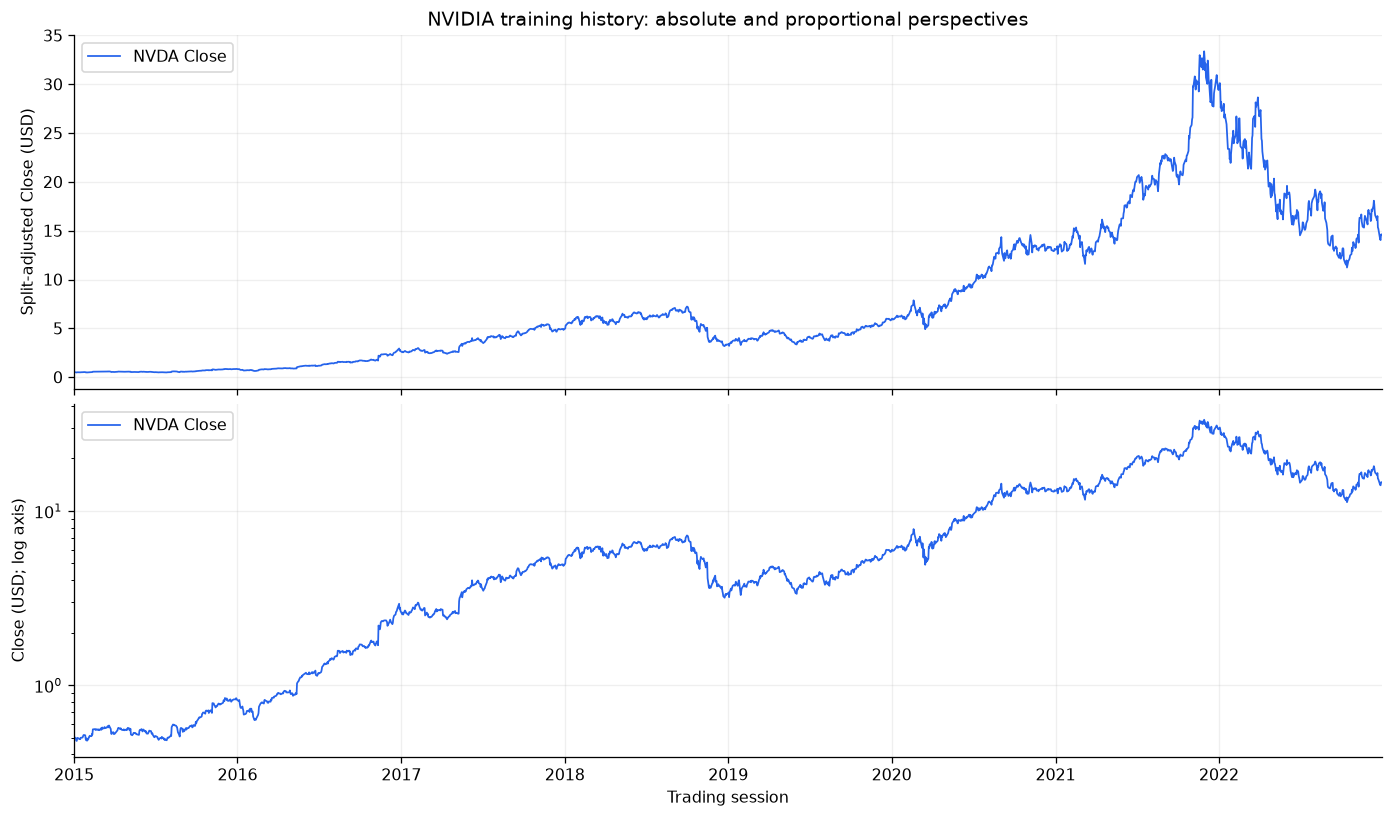

,count,first,last,min,median,max,first_to_last_change_pct
year,,,,,,,
2015,252,0.50325,0.824000,0.47850,0.556625,0.843750,63.735717
2016,252,0.80925,2.668500,0.63050,1.190125,2.933000,229.749763
2017,251,2.55025,4.837500,2.38725,3.897000,5.424000,89.687285
2018,251,4.98375,3.337500,3.17700,6.056000,7.234000,-33.032351
2019,252,3.40550,5.882500,3.19975,4.281875,5.984250,72.735289
2020,253,5.99775,13.055000,4.91000,9.612250,14.562000,117.664970
2021,252,13.11350,29.410999,11.59325,19.206750,33.375999,124.280323
2022,251,30.12100,14.614000,11.22700,17.222000,30.121000,-51.482354


First and last training closes: **0.50325** and **14.61400 USD**. The maximum occurs on **2021-11-29**. Each annual first-to-last percentage excludes the move into that year's first session; it is not a full calendar-year investment return. Changing levels challenge fixed-scale models, but do not show predictable future changes.

The largest within-year first-to-last rise is **229.75% in 2016**. The corresponding change in **2022 is -51.48%**. The sample therefore includes materially different price paths; no common trend or external cause is assumed.

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
for ax in axes:
    ax.plot(close.index, close.NVDA, color=COLORS["NVDA"], linewidth=1.1, label="NVDA Close")
    ax.legend(loc="upper left")
axes[0].set(title="NVIDIA training history: absolute and proportional perspectives", ylabel="Split-adjusted Close (USD)")
axes[1].set(yscale="log", ylabel="Close (USD; log axis)", xlabel="Trading session")
dated_axis(axes[1])
show_figure(fig)
annual_prices = close.NVDA.groupby(close.index.year).agg(["count", "first", "last", "min", "median", "max"])
annual_prices["first_to_last_change_pct"] = 100 * (annual_prices["last"] / annual_prices["first"] - 1)
display(annual_prices.rename_axis("year"))
display(Markdown(f"First and last training closes: **{close.NVDA.iloc[0]:.5f}** and "
    f"**{close.NVDA.iloc[-1]:.5f} USD**. The maximum occurs on **{close.NVDA.idxmax().date()}**. "
    "Each annual first-to-last percentage excludes the move into that year's first session; it is not a full "
    "calendar-year investment return. Changing levels challenge fixed-scale models, but do not show predictable future changes."))
strongest_year = annual_prices.first_to_last_change_pct.idxmax()
latest_year = annual_prices.index.max()
display(Markdown(f"The largest within-year first-to-last rise is **{annual_prices.loc[strongest_year, 'first_to_last_change_pct']:.2f}% in {strongest_year}**. "
    f"The corresponding change in **{latest_year} is {annual_prices.loc[latest_year, 'first_to_last_change_pct']:.2f}%**. "
    "The sample therefore includes materially different price paths; no common trend or external cause is assumed."))

## 8. Daily Dollar Changes, Percentage Returns and Log Returns

For consecutive **observed sessions**:

$$\Delta C_t=C_t-C_{t-1},\qquad r_t=\frac{C_t}{C_{t-1}}-1,\qquad \ell_t=\ln(C_t/C_{t-1})=\ln(1+r_t).$$

Dollar changes measure movement on the USD target scale; percentage returns measure movement relative to the previous price. A fixed percentage move produces a larger dollar change at a higher price. Log returns add across time, whereas simple returns compound through $\prod(1+r_t)$.

**shift(1)** aligns the previous observed session, not the previous calendar day. **pct_change(fill_method=None)** computes fractional changes without filling prices. Multiply by 100 for percentage units. The initial derived value stays missing in the source-aligned table and is excluded only where a valid change is required; no source record is removed.

,previous_close_USD,current_close_USD,dollar_change_USD,simple_return_pct,log_return_times_100
NVDA,0.503250,0.494750,-0.008500,-1.689023,-1.703450
SPY,205.429993,201.720001,-3.709991,-1.805964,-1.822470
XLK,20.635000,20.320000,-0.315001,-1.526535,-1.538307


,count,mean,std,min,25%,50%,75%,max
dollar_change_USD,2013.0,0.007010,0.375007,-2.072001,-0.057750,0.004000,0.080500,3.203001
simple_return_pct,2013.0,0.213071,3.030188,-18.755865,-1.199768,0.246226,1.699604,29.806699
log_return_times_100,2013.0,0.167345,3.016161,-20.771155,-1.207023,0.245924,1.685322,26.087623


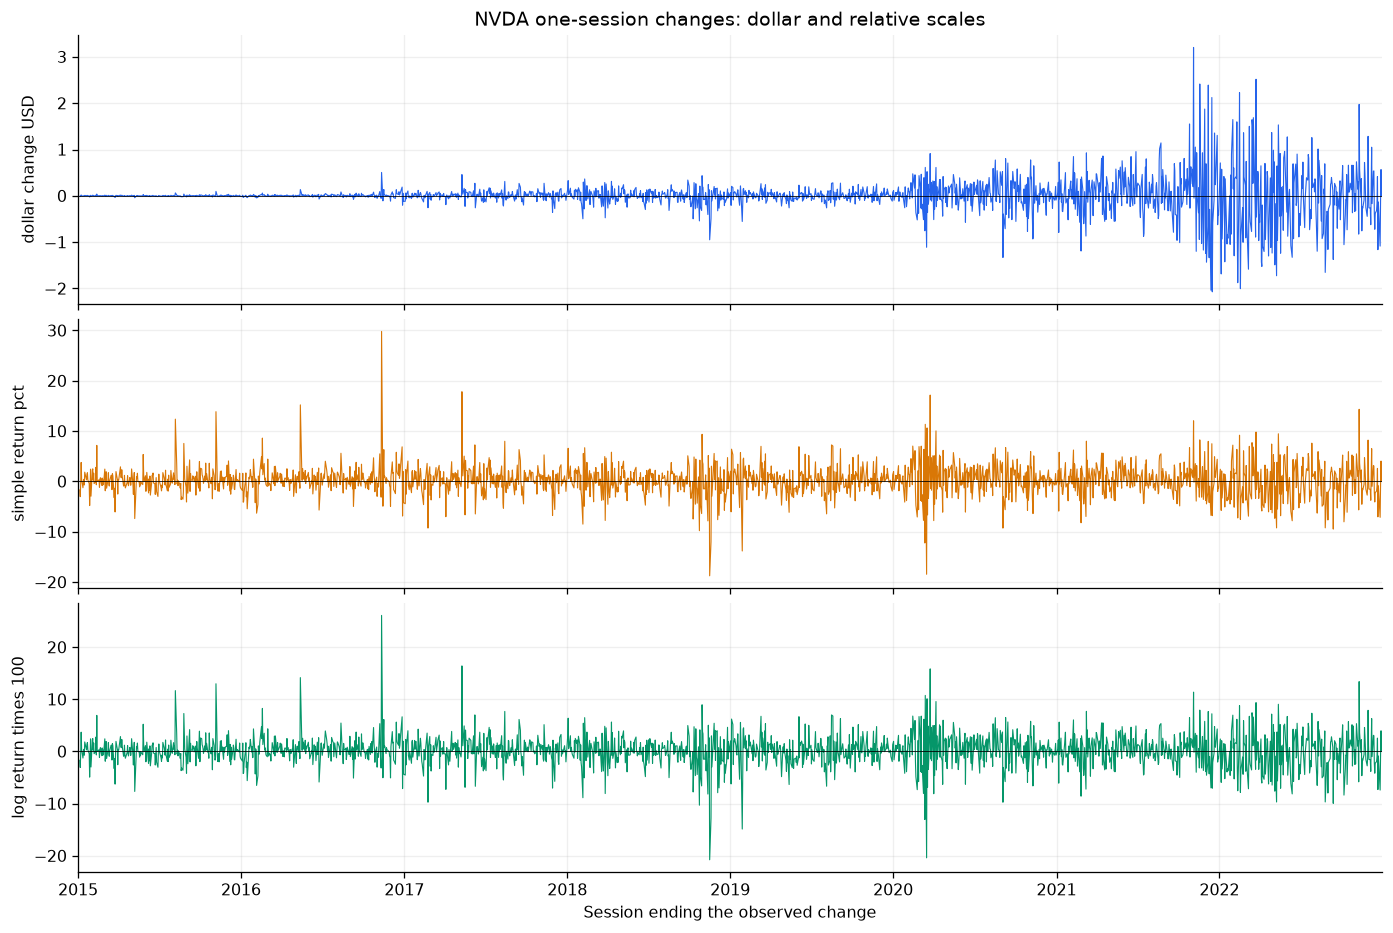

On **2015-01-05**, NVDA moves from **0.503250** to **0.494750 USD**: a **-0.008500 USD** change, **-1.6890%**, or log return **-0.017034**. Simple and log returns are similar for small changes but differ for large moves. These are observed changes; no forecast is generated.

In [10]:
previous_close = close.shift(1)
simple_returns = close.pct_change(fill_method=None)
log_returns = np.log(close / previous_close)
assert dollar_changes.iloc[0].isna().all() and simple_returns.iloc[0].isna().all()
assert simple_returns.iloc[1:].notna().all().all()
assert len(simple_returns.iloc[1:]) == len(stock) - 1
assert np.isfinite(simple_returns.iloc[1:].to_numpy()).all()
assert np.isfinite(log_returns.iloc[1:].to_numpy()).all()
np.testing.assert_allclose(np.log1p(simple_returns.iloc[1:]), log_returns.iloc[1:], atol=1e-14)
np.testing.assert_allclose(np.exp(log_returns.iloc[1:].sum()), close.iloc[-1] / close.iloc[0])
example_date = close.index[1]
calculation = pd.DataFrame({"previous_close_USD": previous_close.loc[example_date],
    "current_close_USD": close.loc[example_date], "dollar_change_USD": dollar_changes.loc[example_date],
    "simple_return_pct": 100 * simple_returns.loc[example_date], "log_return_times_100": 100 * log_returns.loc[example_date]})
display(calculation)
nvda_changes = pd.DataFrame({"dollar_change_USD": dollar_changes.NVDA,
    "simple_return_pct": 100 * simple_returns.NVDA, "log_return_times_100": 100 * log_returns.NVDA})
display(nvda_changes.describe().T)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
for ax, name, color in zip(axes, nvda_changes, ["#2563eb", "#d97706", "#059669"]):
    ax.plot(nvda_changes.index, nvda_changes[name], color=color, linewidth=.7)
    ax.axhline(0, color="black", linewidth=.5)
    ax.set_ylabel(name.replace("_", " "))
axes[0].set_title("NVDA one-session changes: dollar and relative scales")
axes[-1].set_xlabel("Session ending the observed change")
dated_axis(axes[-1])
show_figure(fig)
row = calculation.loc["NVDA"]
display(Markdown(f"On **{example_date.date()}**, NVDA moves from **{row['previous_close_USD']:.6f}** "
    f"to **{row['current_close_USD']:.6f} USD**: a **{row['dollar_change_USD']:.6f} USD** change, "
    f"**{row['simple_return_pct']:.4f}%**, or log return **{row['log_return_times_100']/100:.6f}**. "
    "Simple and log returns are similar for small changes but differ for large moves. "
    "These are observed changes; no forecast is generated."))

## 9. Return Distribution Analysis

Histograms show return frequencies; boxplots show median, quartiles and points beyond conventional whiskers. Here the fences are $Q_1-1.5\,IQR$ and $Q_3+1.5\,IQR$, with $IQR=Q_3-Q_1$. Points beyond them are **flags, not automatic errors**.

Sample skewness describes asymmetry. Excess kurtosis describes tail/peak behaviour relative to a normal reference of zero; it is not a crash probability. Estimates can be sensitive to extremes. The extremes table permits inspection against actual source prices. No clipping, winsorisation or deletion is applied.

The three instruments use common histogram bin boundaries and a common return axis so their dispersion can be compared visually.

The extremes table uses absolute return magnitude to select dates, then retrieves the corresponding original and preceding prices by label. This selection is for inspection; it does not reorder or filter the dataset used elsewhere.


,n,mean_pct,median_pct,sample_SD_pct,skewness,excess_kurtosis,min_pct,max_pct,IQR_flag_count
instrument,,,,,,,,,
NVDA,2013,0.213071,0.246226,3.030188,0.450865,8.387125,-18.755865,29.806699,126
SPY,2013,0.037847,0.051641,1.178136,-0.551840,12.361460,-10.942374,9.060326,156
XLK,2013,0.066295,0.093745,1.511666,-0.210478,9.397696,-13.813998,11.731923,137


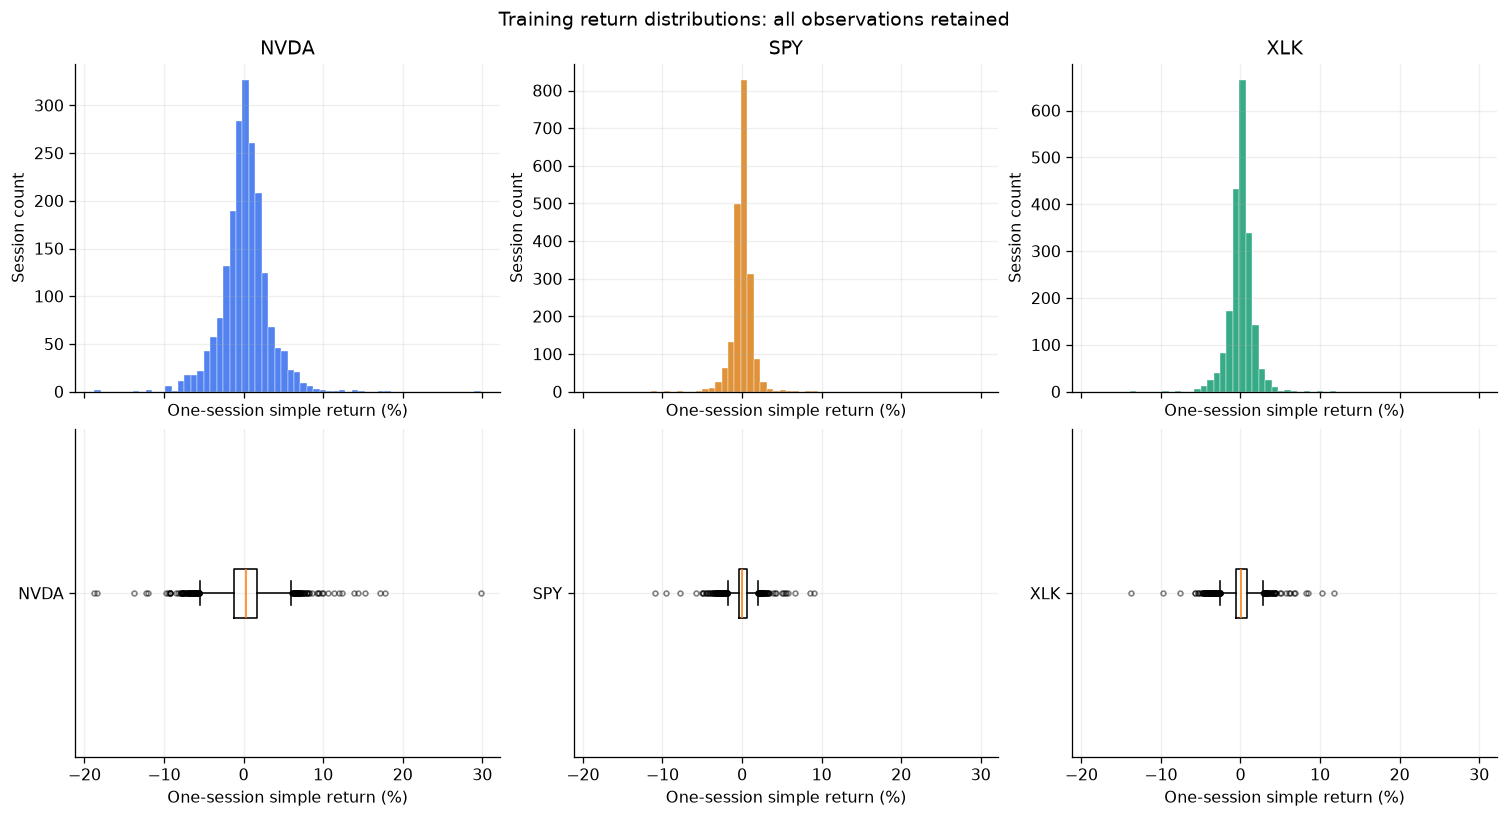

,previous_close_USD,close_USD,dollar_change_USD,simple_return_pct
session,,,,
2016-11-11,1.69425,2.19925,0.50500,29.806699
2018-11-16,5.05975,4.11075,-0.94900,-18.755865
2020-03-16,6.02100,4.91000,-1.11100,-18.452086
2017-05-10,2.57350,3.03225,0.45875,17.825919
2020-03-24,5.31725,6.22950,0.91225,17.156426
2016-05-13,0.88925,1.02450,0.13525,15.209450
2022-11-10,13.77600,15.75000,1.97400,14.329268
2015-11-06,0.69275,0.78875,0.09600,13.857816


NVDA sample skewness is **0.451**, excess kurtosis **8.387**, with **126** returns outside the IQR fences. Extremes are **-18.756%** and **29.807%**. Passing OHLC/date checks does not certify vendor accuracy, but magnitude alone does not justify removal. No event-causation claim is made without separate evidence.

Daily return sample standard deviations are **NVDA: 3.030 percentage points**, **SPY: 1.178 percentage points**, **XLK: 1.512 percentage points**. **NVDA** has the largest dispersion in this sample. Positive excess kurtosis occurs for NVDA, SPY, XLK, indicating pronounced tails relative to a normal reference without establishing a distributional model. A scaling transformation alone does not remove these tails; valid extremes remain part of the forecasting problem.

In [11]:
returns_pct = 100 * simple_returns.iloc[1:]
rows = []
for symbol in SYMBOLS:
    series = returns_pct[symbol]
    q1, q3 = series.quantile([.25, .75])
    iqr = q3 - q1
    rows.append({"instrument": symbol, "n": len(series), "mean_pct": series.mean(),
        "median_pct": series.median(), "sample_SD_pct": series.std(ddof=1),
        "skewness": series.skew(), "excess_kurtosis": series.kurt(),
        "min_pct": series.min(), "max_pct": series.max(),
        "IQR_flag_count": int(((series < q1 - 1.5*iqr) | (series > q3 + 1.5*iqr)).sum())})
distribution = pd.DataFrame(rows).set_index("instrument")
display(distribution)
histogram_bins = np.linspace(returns_pct.to_numpy().min(), returns_pct.to_numpy().max(), 61)
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, layout="constrained")
for column, symbol in enumerate(SYMBOLS):
    series = returns_pct[symbol]
    axes[0, column].hist(series, bins=histogram_bins, color=COLORS[symbol], alpha=.8, edgecolor="white", linewidth=.3)
    axes[0, column].set(title=symbol, xlabel="One-session simple return (%)", ylabel="Session count")
    axes[1, column].boxplot(series, orientation="horizontal", whis=1.5, tick_labels=[symbol],
                           flierprops={"markersize": 3, "alpha": .5})
    axes[1, column].set_xlabel("One-session simple return (%)")
fig.suptitle("Training return distributions: all observations retained")
show_figure(fig)
extreme_dates = returns_pct.NVDA.abs().nlargest(8).index
extremes = pd.DataFrame({"previous_close_USD": previous_close.NVDA.loc[extreme_dates],
    "close_USD": close.NVDA.loc[extreme_dates], "dollar_change_USD": dollar_changes.NVDA.loc[extreme_dates],
    "simple_return_pct": returns_pct.NVDA.loc[extreme_dates]}).rename_axis("session")
display(extremes)
d = distribution.loc["NVDA"]
display(Markdown(f"NVDA sample skewness is **{d['skewness']:.3f}**, excess kurtosis **{d['excess_kurtosis']:.3f}**, "
    f"with **{int(d['IQR_flag_count'])}** returns outside the IQR fences. Extremes are "
    f"**{d['min_pct']:.3f}%** and **{d['max_pct']:.3f}%**. "
    "Passing OHLC/date checks does not certify vendor accuracy, but magnitude alone does not justify removal. "
    "No event-causation claim is made without separate evidence."))
largest_dispersion = distribution.sample_SD_pct.idxmax()
positive_kurtosis = distribution.index[distribution.excess_kurtosis > 0].tolist()
display(Markdown("Daily return sample standard deviations are "
    + ", ".join(f"**{symbol}: {distribution.loc[symbol, 'sample_SD_pct']:.3f} percentage points**" for symbol in SYMBOLS)
    + f". **{largest_dispersion}** has the largest dispersion in this sample. Positive excess kurtosis occurs for "
    + ", ".join(positive_kurtosis)
    + ", indicating pronounced tails relative to a normal reference without establishing a distributional model. "
    "A scaling transformation alone does not remove these tails; valid extremes remain part of the forecasting problem."))

## 10. Rolling Volatility and Time-Series Behaviour

A trailing 20-session sample standard deviation summarises recent variability:

$$s_t(x)=\sqrt{\frac{1}{19}\sum_{i=t-19}^{t}(x_i-\bar{x}_{t,20})^2}.$$

Use **20 complete changes**, minimum 20 observations and **ddof=1**. Windows end at the current session and contain no future values. The first estimate requires 21 prices because the initial change is undefined. Measures are daily-scale and **unannualised**, with no $\sqrt{252}$ multiplier.

Return volatility is in percentage points; dollar-change variability is in USD and also depends on price level. Adjacent windows overlap, so estimates are dependent. These backward-looking descriptions are not future risk forecasts. Annual groups assign changes to their ending session; the first training year lacks the change from the preceding year's final close.

Lag-one correlations describe persistence at one lag, not statistical significance, stationarity, independence or forecasting skill.

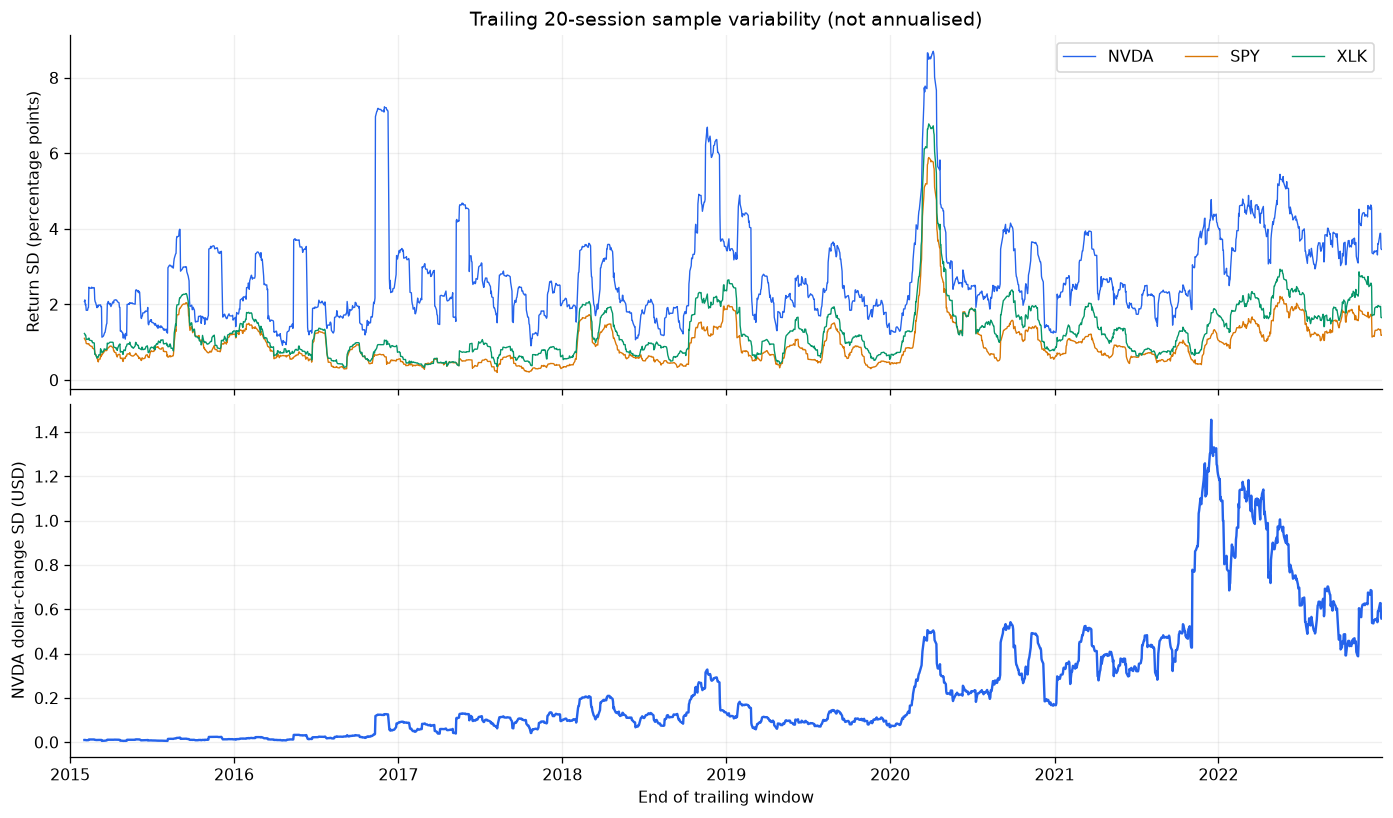

,observed_returns,mean_return_pct,return_SD_pct,dollar_change_SD_USD
year,,,,
2015,251,0.219703,2.177359,0.012902
2016,252,0.507907,2.962464,0.047589
2017,251,0.269021,2.543674,0.090642
2018,251,-0.098449,3.098189,0.166237
2019,252,0.257960,2.558190,0.105286
2020,253,0.382128,3.642571,0.315032
2021,252,0.362479,2.833686,0.620238
2022,251,-0.199479,3.982006,0.766600


,Close_lag1_correlation,log_return_lag1_correlation
NVDA,0.998751,-0.076910
SPY,0.998975,-0.131766
XLK,0.999247,-0.158567


NVDA's trailing return SD ranges from **0.909** to **8.702 percentage points**, peaking on **2020-04-06**. Close lag-one correlation is **0.9988**, versus **-0.0769** for log returns. Level persistence explains the relevance of a last-price benchmark without proving predictable changes. Changing dispersion cautions against assuming a constant noise scale.

Between **2015 and 2022**, annual daily dollar-change SD rises from **0.0129** to **0.7666 USD** (**59.4×**). Daily return SD changes from **2.177** to **3.982 percentage points** (**1.83×**). This contrast shows why a fixed dollar correction has a changing scale even after removing the price-level identity. Residual scaling and forecast errors require explicit evaluation; this contrast does not establish that a return target would perform better.

In [12]:
rolling_return_sd = returns_pct.rolling(20, min_periods=20).std(ddof=1)
rolling_dollar_sd = dollar_changes.rolling(20, min_periods=20).std(ddof=1)
assert rolling_return_sd.NVDA.first_valid_index() == stock.index[20]
assert rolling_dollar_sd.NVDA.first_valid_index() == stock.index[20]
np.testing.assert_allclose(rolling_return_sd.NVDA.loc[stock.index[20]], returns_pct.NVDA.iloc[:20].std(ddof=1))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
for symbol in SYMBOLS:
    axes[0].plot(rolling_return_sd.index, rolling_return_sd[symbol], color=COLORS[symbol], label=symbol, linewidth=.85)
axes[0].set(title="Trailing 20-session sample variability (not annualised)", ylabel="Return SD (percentage points)")
axes[0].legend(ncol=3)
axes[1].plot(rolling_dollar_sd.index, rolling_dollar_sd.NVDA, color=COLORS["NVDA"])
axes[1].set(ylabel="NVDA dollar-change SD (USD)", xlabel="End of trailing window")
dated_axis(axes[1])
show_figure(fig)
annual_behaviour = pd.DataFrame({"observed_returns": returns_pct.NVDA.groupby(returns_pct.index.year).count(),
    "mean_return_pct": returns_pct.NVDA.groupby(returns_pct.index.year).mean(),
    "return_SD_pct": returns_pct.NVDA.groupby(returns_pct.index.year).std(ddof=1),
    "dollar_change_SD_USD": dollar_changes.NVDA.groupby(dollar_changes.index.year).std(ddof=1)})
display(annual_behaviour.rename_axis("year"))
persistence = pd.DataFrame({s: {"Close_lag1_correlation": close[s].autocorr(lag=1),
    "log_return_lag1_correlation": log_returns[s].autocorr(lag=1)} for s in SYMBOLS}).T
display(persistence)
vol = rolling_return_sd.NVDA.dropna()
display(Markdown(f"NVDA's trailing return SD ranges from **{vol.min():.3f}** to **{vol.max():.3f} percentage points**, "
    f"peaking on **{vol.idxmax().date()}**. Close lag-one correlation is "
    f"**{persistence.loc['NVDA', 'Close_lag1_correlation']:.4f}**, versus "
    f"**{persistence.loc['NVDA', 'log_return_lag1_correlation']:.4f}** for log returns. "
    "Level persistence explains the relevance of a last-price benchmark without proving predictable changes. "
    "Changing dispersion cautions against assuming a constant noise scale."))
first_year, last_year = annual_behaviour.index[[0, -1]]
dollar_sd_ratio = annual_behaviour.loc[last_year, "dollar_change_SD_USD"] / annual_behaviour.loc[first_year, "dollar_change_SD_USD"]
return_sd_ratio = annual_behaviour.loc[last_year, "return_SD_pct"] / annual_behaviour.loc[first_year, "return_SD_pct"]
display(Markdown(f"Between **{first_year} and {last_year}**, annual daily dollar-change SD rises "
    f"from **{annual_behaviour.loc[first_year, 'dollar_change_SD_USD']:.4f}** to "
    f"**{annual_behaviour.loc[last_year, 'dollar_change_SD_USD']:.4f} USD** (**{dollar_sd_ratio:.1f}×**). "
    f"Daily return SD changes from **{annual_behaviour.loc[first_year, 'return_SD_pct']:.3f}** to "
    f"**{annual_behaviour.loc[last_year, 'return_SD_pct']:.3f} percentage points** (**{return_sd_ratio:.2f}×**). "
    "This contrast shows why a fixed dollar correction has a changing scale even after removing the price-level identity. "
    "Residual scaling and forecast errors require explicit evaluation; this contrast does not establish that a return target would perform better."))

## 11. NVDA, SPY and XLK Exploratory Relationships

Rebasing uses $B_{s,t}=100C_{s,t}/C_{s,0}$ so each series starts at 100. This descriptive transformation is **not model standardisation** and excludes dividend reinvestment. A log display axis compares proportional growth.

Pearson correlation of aligned log returns measures linear same-session association:

$$\rho_{XY}=\frac{\operatorname{cov}(X,Y)}{s_Xs_Y}.$$

Returns are used instead of trending price levels. Correlation can vary over time and does not establish causation or prove that today's context predicts tomorrow's target. SPY and XLK contain NVDA, so these context series are not independent of it.
The column-wise division aligns each instrument with its own first Close. Return correlations use all shared, defined change observations; date alignment has already been verified, so no missing rows are silently paired across instruments.


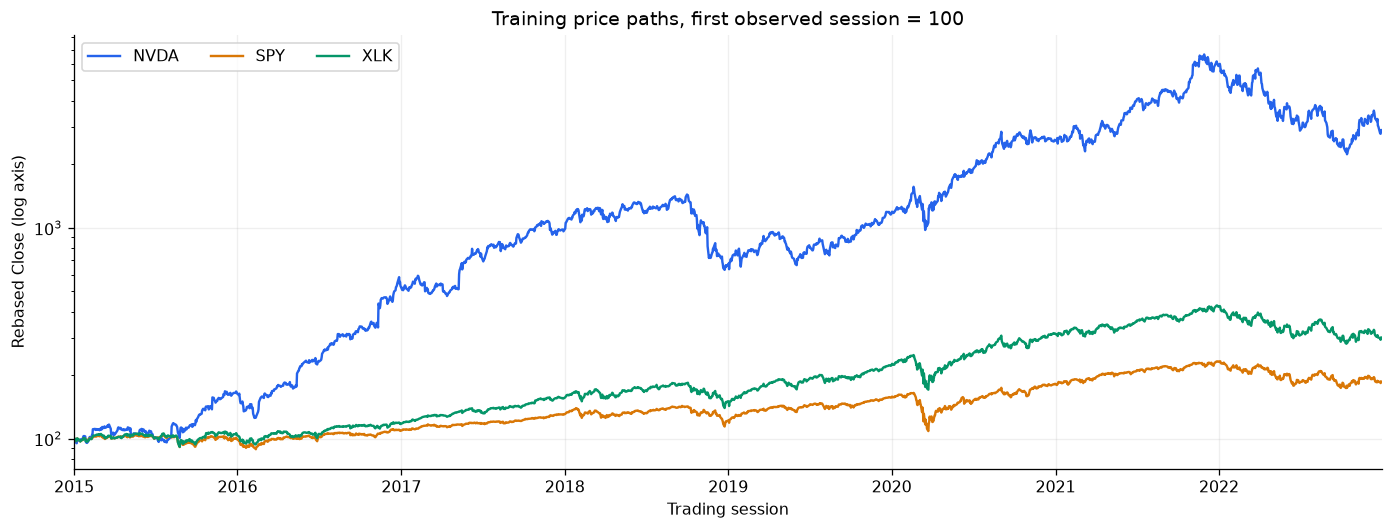

Paired observations per correlation: 2,013


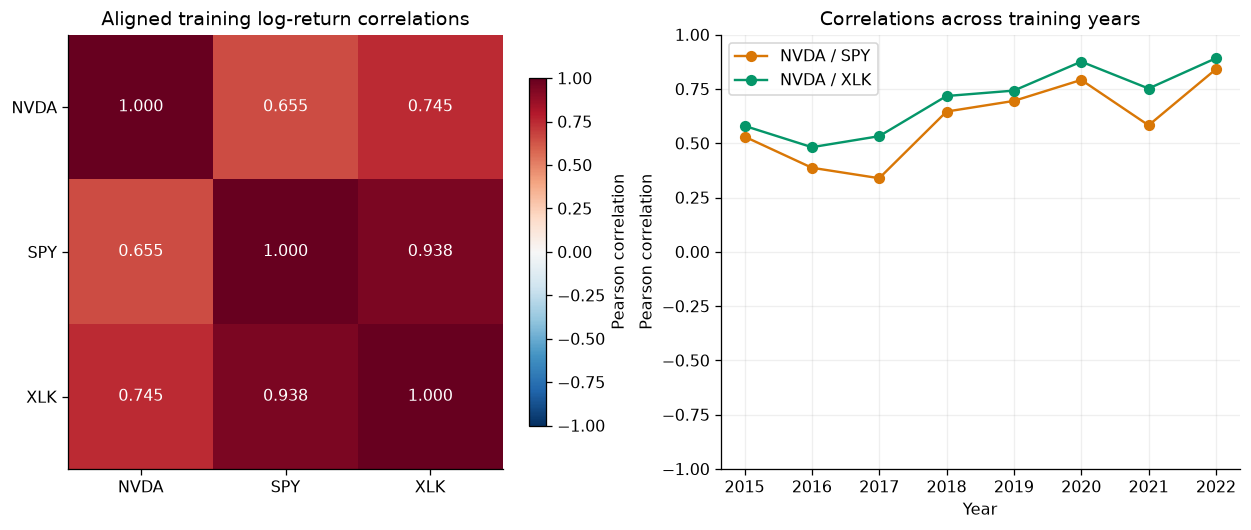

,NVDA,SPY,XLK
NVDA,1.000000,0.655371,0.745461
SPY,0.655371,1.000000,0.938099
XLK,0.745461,0.938099,1.000000


,SPY,XLK
year,,
2015,0.530877,0.580413
2016,0.387396,0.482086
2017,0.339157,0.532816
2018,0.646124,0.717806
2019,0.695216,0.742681
2020,0.791902,0.876049
2021,0.582886,0.752275
2022,0.841348,0.891771


NVDA log-return correlations are **0.655 with SPY** and **0.745 with XLK**; SPY/XLK correlation is **0.938**. These are contemporaneous associations. Predictive value requires a separate controlled forecasting comparison; contemporaneous correlation alone cannot establish it.

In [13]:
rebased = 100 * close.div(close.iloc[0], axis="columns")
np.testing.assert_allclose(rebased.iloc[0], 100)
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for symbol in SYMBOLS:
    ax.plot(rebased.index, rebased[symbol], label=symbol, color=COLORS[symbol])
ax.set(title="Training price paths, first observed session = 100", ylabel="Rebased Close (log axis)",
       yscale="log", xlabel="Trading session")
ax.legend(ncol=3)
dated_axis(ax)
show_figure(fig)
assert log_returns.iloc[1:].notna().all().all()
print(f"Paired observations per correlation: {len(log_returns) - 1:,}")
correlations = log_returns.iloc[1:].corr(method="pearson")
annual_correlations = pd.DataFrame({year: {context: group.NVDA.corr(group[context]) for context in ("SPY", "XLK")}
    for year, group in log_returns.iloc[1:].groupby(log_returns.index[1:].year)}).T
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
im = axes[0].imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].grid(False)
axes[0].set_xticks(range(3), SYMBOLS)
axes[0].set_yticks(range(3), SYMBOLS)
for i in range(3):
    for j in range(3):
        value = correlations.iloc[i, j]
        axes[0].text(j, i, f"{value:.3f}", ha="center", va="center", color="white" if abs(value) > .65 else "black")
axes[0].set_title("Aligned training log-return correlations")
fig.colorbar(im, ax=axes[0], shrink=.8, label="Pearson correlation")
for symbol in ("SPY", "XLK"):
    axes[1].plot(annual_correlations.index, annual_correlations[symbol], marker="o",
                 label=f"NVDA / {symbol}", color=COLORS[symbol])
axes[1].set(title="Correlations across training years", ylabel="Pearson correlation", xlabel="Year", ylim=(-1, 1))
axes[1].legend()
show_figure(fig)
display(correlations)
display(annual_correlations.rename_axis("year"))
display(Markdown(f"NVDA log-return correlations are **{correlations.loc['NVDA','SPY']:.3f} with SPY** "
    f"and **{correlations.loc['NVDA','XLK']:.3f} with XLK**; SPY/XLK correlation is "
    f"**{correlations.loc['SPY','XLK']:.3f}**. These are contemporaneous associations. "
    "Predictive value requires a separate controlled forecasting comparison; "
    "contemporaneous correlation alone cannot establish it."))

## 12. Critical EDA Findings and Modelling Implications

The table connects calculated evidence to methodological implications. A clean audit supports retaining the observations. Changing price and movement scales, extreme returns and market associations identify modelling challenges without establishing which forecasting method will perform best. Implementation choices must be evaluated through controlled comparisons using the stated temporal boundaries.

SMA and EMA summarise historical price levels, RSI summarises the balance of gains and losses, and MACD contrasts differently smoothed prices. Normalising price-based indicators relative to Close and defining RSI with Wilder smoothing provide explicit, reproducible feature conventions. These deterministic transformations do not create independent information. Causal calculation, explicit warm-up exclusions and common eligible windows are necessary for interpretable feature comparisons. SPY/XLK log returns must be observable at the forecast origin. This EDA cannot establish incremental predictive value or individual indicator importance.

Descriptive statistics across the full training period must not replace transformations fitted only on the fitting subset of an internal chronological split. For example, if 2022 is an internal holdout, its observations must be excluded when fitting those transformations. EDA does not provide independent model-selection evidence; alternative targets or scaling methods require controlled evaluation.

In [14]:
findings = pd.DataFrame([
    {"Evidence": "Synthetic tests verify that excluded quote tokens are not decoded",
     "Assessment": "Numerical validation depends only on permitted observations.",
     "Research implication": "Bound price decoding before validation; use shared loading and quality functions."},
    {"Evidence": f"{len(stock):,} aligned sessions; zero missing/unexpected calendar sessions and invalid rows",
     "Assessment": "No observed basis for imputation, resampling or deletion.",
     "Research implication": "Retain original observations, separate calendar coverage checks and fail-fast validation."},
    {"Evidence": f"NVDA Close range {nv['min']:.4f}–{nv['max']:.4f} USD; dollar SD ratio {dollar_sd_ratio:.1f}× across endpoint years",
     "Assessment": "Price and movement scales vary; USD residuals do not remove all distribution shift.",
     "Research implication": "Use training-only scaling; assess residual-target limitations and alternatives through controlled evaluation."},
    {"Evidence": f"Lag-1 correlation: Close {persistence.loc['NVDA','Close_lag1_correlation']:.4f}, log return {persistence.loc['NVDA','log_return_lag1_correlation']:.4f}",
     "Assessment": "Persistent levels make visual tracking insufficient evidence of skill.",
     "Research implication": "Use a naive last-Close comparator and evaluate errors on identical future target dates."},
    {"Evidence": f"{len(stock)} prices permit {len(stock)-config['initial_sequence_length']} 30-session windows",
     "Assessment": "The next-session label must occur after every input observation.",
     "Research implication": "Use target-date chronological partitions and inputs available at each forecast origin."},
    {"Evidence": f"{int(d['IQR_flag_count'])} NVDA returns outside 1.5-IQR fences",
     "Assessment": "Large movements are not automatically data errors; absolute and squared errors emphasise them differently.",
     "Research implication": "Retain valid extremes and MAE/RMSE reporting; no clipping or removal is supported."},
    {"Evidence": f"NVDA/SPY correlation {correlations.loc['NVDA','SPY']:.3f}; NVDA/XLK {correlations.loc['NVDA','XLK']:.3f}",
     "Assessment": "Contemporaneous association is a rationale for investigation, not demonstrated predictive improvement.",
     "Research implication": "Evaluate features through controlled comparisons with causal calculations and common warm-up eligibility; do not infer importance from correlation."},
    {"Evidence": "Split continuity, distinct Adjusted Close, unresolved volume adjustment semantics",
     "Assessment": "Internal consistency does not certify point-in-time histories or the volume convention.",
     "Research implication": "Retain split-adjusted Close without reapplying adjustments; volume remains excluded."},
])
with pd.option_context("display.max_colwidth", None):
    display(findings)

for name, frame in {"close": close, "changes": dollar_changes, "simple_returns": simple_returns,
                    "log_returns": log_returns, "rolling_return_sd": rolling_return_sd,
                    "rolling_dollar_sd": rolling_dollar_sd, "rebased": rebased}.items():
    assert frame.index.min() >= START and frame.index.max() <= END, name
summary = {"analysis_period": {"first": str(stock.index.min().date()), "last": str(stock.index.max().date()),
                              "observations_per_instrument": len(stock)},
           "source_prices_decoded_through": str(END.date()), "test_targets_decoded": False,
           "new_models_fitted": 0, "quality": quality.to_dict(orient="index"),
           "calendar": calendar_summary.to_dict(orient="index"),
           "nvda_close_statistics": close_summary.loc["NVDA"].to_dict(),
           "return_distribution": distribution.to_dict(orient="index"),
           "log_return_correlations": correlations.to_dict(),
           "lag_one_correlations": persistence.to_dict(orient="index"),
           "nvda_rolling_return_sd_pct": {"min": float(vol.min()), "max": float(vol.max()),
                                          "max_date": str(vol.idxmax().date())},
           "annual_nvda_behaviour": {str(year): row.to_dict() for year, row in annual_behaviour.iterrows()}}
print("Training-boundary checks passed; no model experiment executed.")

,Evidence,Assessment,Research implication
0,Synthetic tests verify that excluded quote tokens are not decoded,Numerical validation depends only on permitted observations.,Bound price decoding before validation; use shared loading and quality functions.
1,"2,014 aligned sessions; zero missing/unexpected calendar sessions and invalid rows","No observed basis for imputation, resampling or deletion.","Retain original observations, separate calendar coverage checks and fail-fast validation."
2,NVDA Close range 0.4785–33.3760 USD; dollar SD ratio 59.4× across endpoint years,Price and movement scales vary; USD residuals do not remove all distribution shift.,Use training-only scaling; assess residual-target limitations and alternatives through controlled evaluation.
3,"Lag-1 correlation: Close 0.9988, log return -0.0769",Persistent levels make visual tracking insufficient evidence of skill.,Use a naive last-Close comparator and evaluate errors on identical future target dates.
4,2014 prices permit 1984 30-session windows,The next-session label must occur after every input observation.,Use target-date chronological partitions and inputs available at each forecast origin.
5,126 NVDA returns outside 1.5-IQR fences,Large movements are not automatically data errors; absolute and squared errors emphasise them differently.,Retain valid extremes and MAE/RMSE reporting; no clipping or removal is supported.
6,NVDA/SPY correlation 0.655; NVDA/XLK 0.745,"Contemporaneous association is a rationale for investigation, not demonstrated predictive improvement.",Evaluate features through controlled comparisons with causal calculations and common warm-up eligibility; do not infer importance from correlation.
7,"Split continuity, distinct Adjusted Close, unresolved volume adjustment semantics",Internal consistency does not certify point-in-time histories or the volume convention.,Retain split-adjusted Close without reapplying adjustments; volume remains excluded.


Training-boundary checks passed; no model experiment executed.


**Limitations.** These checks establish specified internal consistency, not independent vendor accuracy, point-in-time data availability or investment performance. Split adjustment is retrospective, the ETF calendar is a proxy, and volume semantics remain unresolved. Distribution summaries and correlations describe a finite, dependent sample.

The findings support retaining the observed records and the split-adjusted Close convention. Bounded loading restricts numerical inspection to the training interval; shared diagnostics and independent calendar checks assess complementary aspects of data quality. No observations are imputed or removed. The reserved test interval has no role in these calculations, and no model is fitted in this notebook.

**Reference:** [Data conventions](../docs/DATA_CONVENTIONS.md).